# 06 · Functional annotation of AT2 metaprograms

Functional characterisation of the 37 healthy AT2 metaprograms (paper Methods: *Non-malignant lung single cell data processing*; Results, Figure 1G; Table s1, Table s3).

**Input**
- `adata_normal_score.h5ad`: AT2 cells with metaprogram scores, written by **File 08** (run File 08 first)
- `intermediate_files/lung/metaprograms_gene_sets_healthy_lung_figs_min5.gmt`: AT2 metaprograms (File 05b)
- `cancer_mps.gmt`: malignant metaprograms from Gavish *et al.* 2023 (used in section 2 only; will be added to this repository)

**Steps**
1. Dominant metaprogram per cell and metaprogram composition per sample, for the AT2 and malignant metaprograms.
2. Enrichment of each AT2 metaprogram against MSigDB Hallmark 2020 with Enrichr (`gseapy.enrichr`, requires internet access): all significant terms (adjusted p < 0.01) among the top 5 per metaprogram (Figure 1G, option A), plus the top term per metaprogram for comparison (option B).
3. Hallmark terms of the AT2 metaprograms enriched in each malignant subpopulation (Groups 0–3, Table s3).

**Note**: sections 3–5 were re-run on 20 October 2026 after fixing a row-selection bug in the enrichment step (details in section 3). **TODO (paper): update Figure 1G and Table s3 to these corrected results.**

## Setup

In [1]:
import random

import gseapy as gp
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.express as px
import scanpy as sc
from scipy.stats import entropy
from sklearn.cluster import KMeans

random.seed(1)

In [2]:
# Paths: edit to match your environment
SCORED_H5AD = "adata_normal_score.h5ad"                                                # output of File 08
HEALTHY_MP_GMT = "intermediate_files/lung/metaprograms_gene_sets_healthy_lung_figs_min5.gmt"  # File 05b
CANCER_MP_GMT = "/path/to/cancer_mps.gmt"                                             # Gavish et al. 2023 metaprograms

## 1. Load scored AT2 cells

In [3]:
adata = sc.read(SCORED_H5AD)

In [4]:
adata

AnnData object with n_obs × n_vars = 115666 × 31710
    obs: 'Unnamed: 0', 'suspension_type', 'donor_id', 'is_primary_data', 'assay_ontology_term_id', 'cell_type_ontology_term_id', 'development_stage_ontology_term_id', 'disease_ontology_term_id', 'self_reported_ethnicity_ontology_term_id', 'tissue_ontology_term_id', 'organism_ontology_term_id', 'sex_ontology_term_id', "3'_or_5'", 'BMI', 'age_or_mean_of_age_range', 'age_range', 'anatomical_region_ccf_score', 'ann_coarse_for_GWAS_and_modeling', 'ann_finest_level', 'ann_level_1', 'ann_level_2', 'ann_level_3', 'ann_level_4', 'ann_level_5', 'cause_of_death', 'core_or_extension', 'dataset', 'fresh_or_frozen', 'log10_total_counts', 'lung_condition', 'mixed_ancestry', 'original_ann_level_1', 'original_ann_level_2', 'original_ann_level_3', 'original_ann_level_4', 'original_ann_level_5', 'original_ann_nonharmonized', 'reannotation_type', 'sample', 'scanvi_label', 'sequencing_platform', 'smoking_status', 'study', 'subject_type', 'tissue_coarse_un

## 2. Metaprogram composition per sample

In [5]:
def parse_gmt(gmt_path):
    """Parses a GMT file into a dictionary of signature name -> gene list."""
    signatures = {}
    with open(gmt_path, 'r') as f:
        for line in f:
            parts = line.strip().split('\t')
            if len(parts) >= 3:
                sig_name = parts[0]
                genes = [g for g in parts[2:] if g]
                signatures[sig_name] = genes
    return signatures

def analyze_both_gmt_proportions(adata, gmt_path_1, gmt_path_2, patient_col='sample', group_col='leiden_samples'):
    """
    Scores cells, calculates individual tumor proportions, evaluates exact tumor presence counts,
    computes normalized Shannon entropy (mixture balance), discovers KMeans subtypes, 
    and exports comprehensive statistics and stacked bar plots.
    """
    var_idx = adata.var_index if hasattr(adata, 'var_index') else adata.var.index
    
    gmt_dict = {
        'Healthy_Lung': gmt_path_1,
        'Cancer_MPs': gmt_path_2
    }
    
    all_stats = {}

    for label, path in gmt_dict.items():
        signatures = parse_gmt(path)
        score_cols = []
        
        for sig_name, gene_list in signatures.items():
            valid_genes = [g for g in gene_list if g in var_idx]
            if len(valid_genes) > 5:
                col_name = f'{label}_{sig_name}_score'
                sc.tl.score_genes(adata, valid_genes, score_name=col_name)
                score_cols.append(col_name)
                
        if not score_cols:
            print(f"⚠ No valid genes found for {label}.")
            continue
            
        # Determine dominant MP for this specific GMT set
        dom_col = f'dominant_{label}'
        adata.obs[dom_col] = adata.obs[score_cols].idxmax(axis=1)
        adata.obs[dom_col] = adata.obs[dom_col].str.replace(f'{label}_', '').str.replace('_score', '')
        
        # 1. Percentage of cells belonging to each MP per individual tumor
        prop_df = pd.crosstab(adata.obs[patient_col], adata.obs[dom_col], normalize='index') * 100
        prop_df = prop_df.fillna(0)
        
        # Map patient to group (e.g., leiden_samples)
        if group_col in adata.obs.columns:
            patient_to_group = adata.obs.drop_duplicates(subset=[patient_col]).set_index(patient_col)[group_col].to_dict()
            prop_df['Group'] = prop_df.index.map(patient_to_group)
        else:
            prop_df['Group'] = 'Unknown'
            
        plot_df = prop_df.drop(columns=['Group'])
        mp_cols = list(plot_df.columns)
        total_patients = len(plot_df)

        # 2. Abundance, Range, Variability, and Exact Tumor Presence Counts (>0%)
        presence_count = (plot_df > 0).sum(axis=0)
        presence_pct = (plot_df > 0).mean(axis=0) * 100

        summary_stats = pd.DataFrame({
            'Mean_%': plot_df[mp_cols].mean(),
            'Min_%': plot_df[mp_cols].min(),
            'Max_%': plot_df[mp_cols].max(),
            'Std_Dev': plot_df[mp_cols].std(),
            'Tumors_Present': presence_count,
            'Total_Tumors': total_patients,
            'Presence_Percentage': presence_pct
        }).sort_values(by='Mean_%', ascending=False)
        
        print(f"\n--- Abundance, Range, Variability & Presence ({label}) ---")
        print(summary_stats.to_string())

        # 3. Inter-tumoral Mixture Balance via Normalized Shannon Entropy
        prop_fractions = plot_df / 100
        raw_entropy = entropy(prop_fractions, axis=1)
        max_ent = np.log(len(mp_cols)) if len(mp_cols) > 0 else 1
        normalized_entropy = raw_entropy / max_ent
        
        prop_df['MP_Entropy'] = normalized_entropy
        prop_df['Mixture_Category'] = pd.Series(normalized_entropy, index=prop_df.index).apply(
            lambda x: 'Balanced Mixture' if x > 0.6 else ('Dominated Mixture' if x < 0.3 else 'Intermediate')
        )
        
        mixture_counts = prop_df['Mixture_Category'].value_counts(normalize=True) * 100
        print(f"\n--- Mixture Balance Breakdown ({label}) ---")
        print(mixture_counts)

        # 4. MP Composition Subtypes via Unsupervised KMeans Clustering
        kmeans = KMeans(n_clusters=3, random_state=42)
        prop_df['Composition_Subtype'] = kmeans.fit_predict(plot_df)
        
        subtype_counts = prop_df['Composition_Subtype'].value_counts(normalize=True) * 100
        print(f"\n--- Fraction of Patients per Composition Subtype ({label}) ---")
        print(subtype_counts)
        
        cluster_profiles = plot_df.groupby(prop_df['Composition_Subtype'])[mp_cols].mean()
        print(f"\n--- Subtype Profiles (Mean MP % per Cluster) ({label}) ---")
        print(cluster_profiles.T.to_string())
            
        # COMPUTE STATISTICS PER GROUP (LEIDEN_SAMPLES) AND METAPROGRAM
        stats_records = []
        for group_val, group_subset in prop_df.groupby('Group'):
            for mp in mp_cols:
                stats_records.append({
                    'GMT_Source': label,
                    'Group': group_val,
                    'Metaprogram': mp,
                    'Mean_Proportion': group_subset[mp].mean(),
                    'Std_Dev': group_subset[mp].std(),
                    'Min': group_subset[mp].min(),
                    'Max': group_subset[mp].max(),
                    'N_Samples': len(group_subset)
                })
        
        stats_df = pd.DataFrame(stats_records)
        all_stats[label] = stats_df
        
        # Save statistics to CSV
        csv_filename = f'mp_statistics_{label.lower()}.csv'
        stats_df.to_csv(csv_filename, index=False)
        print(f"\n✓ Saved statistics: {csv_filename}")
        
        # Plot 100% stacked bar chart
        fig, ax = plt.subplots(figsize=(14, 6))
        plot_df.plot(kind='bar', stacked=True, ax=ax, colormap='tab20', width=0.8)
        
        ax.set_title(f'Metaprogram Proportions Across Patients ({label})', fontsize=13, fontweight='bold')
        ax.set_xlabel('Patient Sample', fontsize=11)
        ax.set_ylabel('Cell Proportion (%)', fontsize=11)
        ax.legend(bbox_to_anchor=(1.05, 1), loc='upper left', fontsize=8)
        
        plt.tight_layout()
        filename = f'17_mp_patient_proportions_{label.lower()}_stacked.svg'
        plt.savefig(filename, dpi=300, bbox_inches='tight')
        plt.close()
        print(f"✓ Saved plot: {filename}")
        
    return all_stats

In [6]:
all_stats = analyze_both_gmt_proportions(adata, HEALTHY_MP_GMT, CANCER_MP_GMT, patient_col='sample')


--- Abundance, Range, Variability & Presence (Healthy_Lung) ---
                          Mean_%  Min_%      Max_%    Std_Dev  Tumors_Present  Total_Tumors  Presence_Percentage
dominant_Healthy_Lung                                                                                           
MP33                   17.499250    0.0  68.934911  15.950492             142           148            95.945946
MP2                    14.197618    0.0  77.339901  16.289084             131           148            88.513514
MP4                    11.706489    0.0  92.261905  16.257215             131           148            88.513514
MP20                   10.980002    0.0  91.961023  25.618235              49           148            33.108108
MP3                    10.552065    0.0  64.480874  13.974605             128           148            86.486486
MP11                    5.418526    0.0  62.698413   9.366882             111           148            75.000000
MP15                    4.87509

## 3. Hallmark enrichment of AT2 metaprograms (Figure 1G)

> **Bug fix and re-run (20 October 2026).** In the original analysis, the per-metaprogram Enrichr results were concatenated without resetting the row index, so `combined_results.loc[idx]` picked rows from every metaprogram that shared an index label. The resulting term table was an inconsistent subset of the significant terms (42 of 83 metaprogram–term pairs). Sections 3–5 were re-run with the fix below; sections 1–2 keep their original outputs. Re-running the original code reproduced the original table exactly, so the Enrichr results themselves are unchanged.
>
> **TODO (paper): update Figure 1G and Table s3** to the corrected results below (option A).

Each metaprogram (≥ 5 genes) is tested against MSigDB Hallmark 2020 with Enrichr (`gseapy.enrichr`, requires internet access). The top 5 terms per metaprogram are kept and filtered at adjusted p < 0.01.

In [7]:
gmt_file = HEALTHY_MP_GMT

# Read a GMT file into {gene set name: genes}
def read_gmt(file_path):
    gene_signatures = {}
    with open(file_path, 'r') as f:
        for line in f:
            parts = line.strip().split('\t')
            gene_set_name = parts[0]
            genes = parts[2:]  # Skip the first two columns (gene set name and description)
            gene_signatures[gene_set_name] = genes
    return gene_signatures

# Read gene signatures from GMT file
gene_signatures = read_gmt(gmt_file)

gene_signatures = {k: v for k, v in gene_signatures.items() if len(v) > 4}

# Enrichr library used for enrichment
gene_sets = ['MSigDB_Hallmark_2020']

# Function to perform enrichment analysis for a single gene signature
def get_top_pathways(genes, gene_sets, top_n=5):
    enr = gp.enrichr(gene_list=genes, gene_sets=gene_sets)
    results = enr.results
    top_pathways = results.head(top_n)
    return top_pathways

# Store results for all gene signatures
all_results = []

for gene_set_name, genes in gene_signatures.items():
    top_pathways = get_top_pathways(genes, gene_sets)
    top_pathways['Gene_Signature'] = gene_set_name
    all_results.append(top_pathways)

# Combine all results into a single DataFrame
combined_results = pd.concat(all_results)

In [8]:
# Keep significant terms; reset the index so that every row has a unique label (the fix)
combined_results = combined_results[combined_results['Adjusted P-value'] < 0.01].reset_index(drop=True)

# Order metaprograms numerically (MP1, MP2, ..., MP42)
mp_order = sorted(combined_results['Gene_Signature'].unique(), key=lambda s: int(s[2:]))
combined_results['Gene_Signature'] = pd.Categorical(combined_results['Gene_Signature'], categories=mp_order, ordered=True)
combined_results['Odds Ratio Log'] = np.log10(combined_results['Odds Ratio'] + 1)

print(f"{len(combined_results)} significant metaprogram–term pairs across {combined_results['Gene_Signature'].nunique()} metaprograms "
      f"and {combined_results['Term'].nunique()} Hallmark terms")
combined_results[['Gene_Signature', 'Term', 'Overlap', 'Adjusted P-value', 'Odds Ratio', 'Combined Score', 'Genes']]

83 significant metaprogram–term pairs across 24 metaprograms and 27 Hallmark terms


,Gene_Signature,Term,Overlap,Adjusted P-value,Odds Ratio,Combined Score,Genes
0,MP1,Estrogen Response Late,3/200,8.456552e-03,21.522117,159.519160,CAV1;TNNC1;EMP2
1,MP3,TNF-alpha Signaling via NF-kB,9/200,1.488260e-16,932.937173,36696.268154,EGR1;JUN;ZFP36;BTG2;GADD45B;DUSP1;FOS;JUNB;IER2
2,MP3,Hypoxia,4/200,1.749651e-05,67.326531,885.393278,JUN;ZFP36;DUSP1;FOS
3,MP3,UV Response Up,3/158,2.652423e-04,54.843318,537.187002,BTG2;FOS;JUNB
4,MP3,Apoptosis,3/161,2.652423e-04,53.793852,523.895326,JUN;BTG2;GADD45B
...,...,...,...,...,...,...,...
78,MP40,Apical Junction,3/200,1.640706e-03,25.111675,195.844021,BMP1;ICAM4;ICAM1
79,MP41,Estrogen Response Late,3/200,5.619703e-03,27.395939,219.569955,CAV1;SEMA3B;EMP2
80,MP42,Epithelial Mesenchymal Transition,3/200,1.541562e-04,100.492386,1091.044408,LGALS1;MGP;VIM
81,MP42,Myogenesis,2/200,3.876189e-03,49.989899,326.620610,GPX3;IGFBP7


### Option A: all significant terms per metaprogram (Figure 1G)

Stacked bars show every significant Hallmark term per metaprogram; bar height is log10(odds ratio + 1). The palette is extended to 48 colours because there are 27 distinct terms.

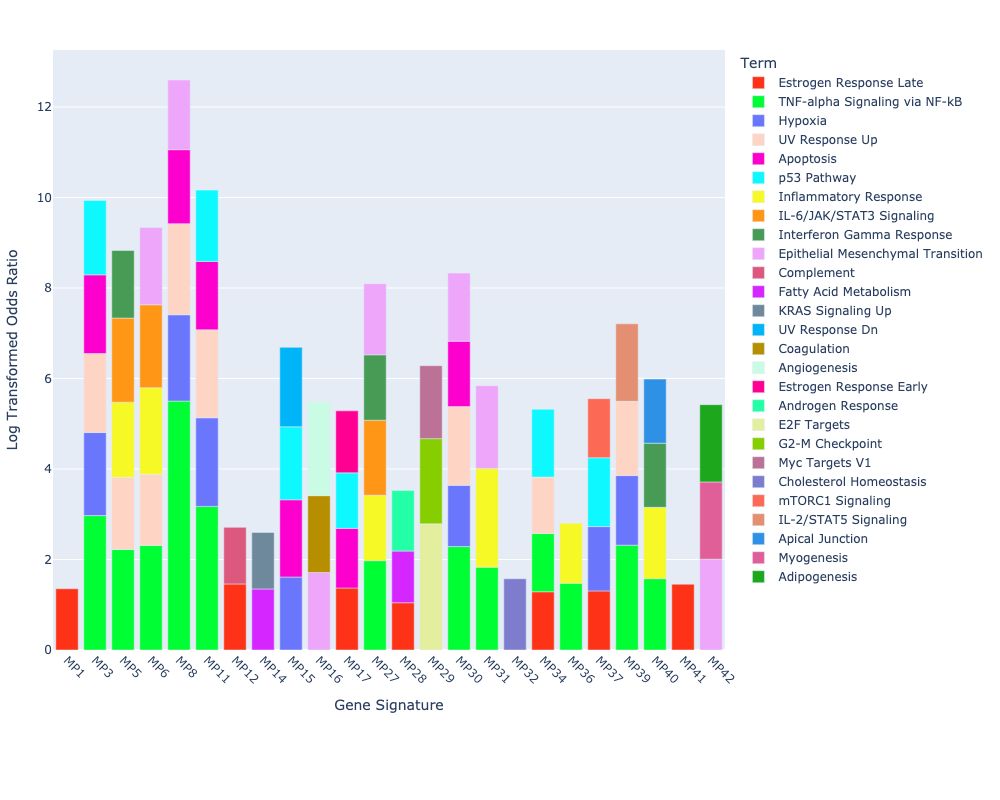

In [9]:
fig = px.bar(
    combined_results.sort_values('Gene_Signature'),
    x='Gene_Signature',
    y='Odds Ratio Log',
    color='Term',
    height=800,
    width=1000,
    color_discrete_sequence=px.colors.qualitative.Light24 + px.colors.qualitative.Dark24,
    category_orders={'Gene_Signature': mp_order},
)
fig.update_layout(
    xaxis_title='Gene Signature',
    yaxis_title='Log Transformed Odds Ratio',
    legend_title='Term',
    xaxis_tickangle=45,
    margin=dict(l=50, r=50, t=50, b=150),
)
fig.show()
fig.write_image("figures/odds_ratio_plot.svg", format='svg')

### Option B: top term per metaprogram

The single term with the highest Enrichr Combined Score for each metaprogram (for comparison; not used downstream).

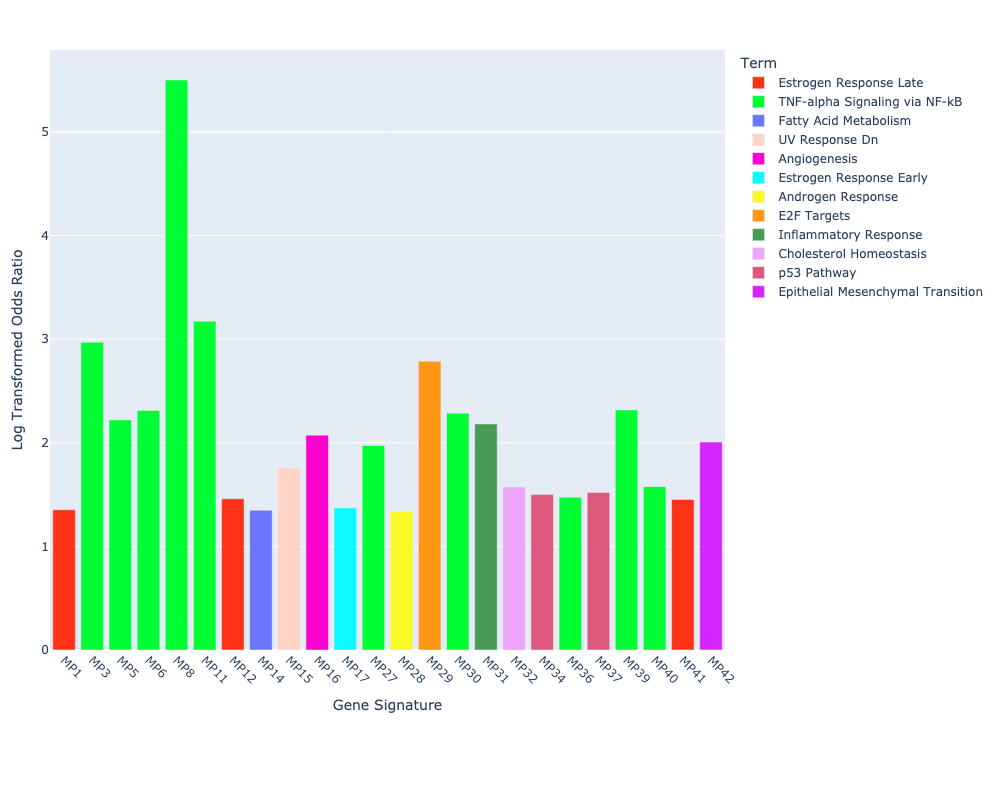

,Gene_Signature,Term,Adjusted P-value,Combined Score
0,MP1,Estrogen Response Late,8.456552e-03,1.595192e+02
1,MP3,TNF-alpha Signaling via NF-kB,1.488260e-16,3.669627e+04
6,MP5,TNF-alpha Signaling via NF-kB,1.499475e-12,4.926475e+03
11,MP6,TNF-alpha Signaling via NF-kB,8.358542e-10,4.755456e+03
16,MP8,TNF-alpha Signaling via NF-kB,9.753361e-32,2.353681e+07
21,MP11,TNF-alpha Signaling via NF-kB,1.684779e-26,9.274696e+04
26,MP12,Estrogen Response Late,7.563718e-06,4.184589e+02
28,MP14,Fatty Acid Metabolism,9.177188e-03,1.588763e+02
30,MP15,UV Response Dn,4.548630e-03,3.832343e+02
36,MP16,Angiogenesis,8.222391e-04,9.964997e+02


In [10]:
top_term = combined_results.loc[combined_results.groupby('Gene_Signature', observed=True)['Combined Score'].idxmax()]

fig = px.bar(
    top_term,
    x='Gene_Signature',
    y='Odds Ratio Log',
    color='Term',
    height=800,
    width=1000,
    color_discrete_sequence=px.colors.qualitative.Light24,
    category_orders={'Gene_Signature': mp_order},
)
fig.update_layout(
    xaxis_title='Gene Signature',
    yaxis_title='Log Transformed Odds Ratio',
    legend_title='Term',
    xaxis_tickangle=45,
    margin=dict(l=50, r=50, t=50, b=150),
)
fig.show()
fig.write_image("figures/odds_ratio_plot_top_term.svg", format='svg')

top_term[['Gene_Signature', 'Term', 'Adjusted P-value', 'Combined Score']]

## 4. Hallmark terms per AT2 metaprogram (option A)

In [11]:
df = combined_results[['Gene_Signature', 'Term']].sort_values(['Gene_Signature', 'Term']).reset_index(drop=True)
df.to_csv('mp_hallmark_terms.csv', index=False)
df

,Gene_Signature,Term
0,MP1,Estrogen Response Late
1,MP3,Apoptosis
2,MP3,Hypoxia
3,MP3,TNF-alpha Signaling via NF-kB
4,MP3,UV Response Up
...,...,...
78,MP40,TNF-alpha Signaling via NF-kB
79,MP41,Estrogen Response Late
80,MP42,Adipogenesis
81,MP42,Epithelial Mesenchymal Transition


## 5. AT2 metaprograms enriched in each malignant subpopulation (Table s3)

Metaprograms per group are taken from the malignant-subpopulation analysis; Group 0 metaprograms MP4, MP10, MP19, MP20 and MP35 have no significant Hallmark term.

In [12]:
# Group 0
target_genes = ['MP34', 'MP3', 'MP8', 'MP4', 'MP11', 'MP10', 'MP20', 'MP35', 'MP19']

# Filter the DataFrame
df_group_0 = df[df['Gene_Signature'].isin(target_genes)]
df_group_0

,Gene_Signature,Term
1,MP3,Apoptosis
2,MP3,Hypoxia
3,MP3,TNF-alpha Signaling via NF-kB
4,MP3,UV Response Up
5,MP3,p53 Pathway
16,MP8,Apoptosis
17,MP8,Epithelial Mesenchymal Transition
18,MP8,Hypoxia
19,MP8,TNF-alpha Signaling via NF-kB
20,MP8,UV Response Up


In [13]:
# Group 1
target_genes_group1= ["MP17",
"MP31",
"MP15",
"MP27"]

# Filter the DataFrame
df_group_1 = df[df['Gene_Signature'].isin(target_genes_group1)]
df_group_1

,Gene_Signature,Term
30,MP15,Apoptosis
31,MP15,Hypoxia
32,MP15,UV Response Dn
33,MP15,p53 Pathway
37,MP17,Apoptosis
38,MP17,Estrogen Response Early
39,MP17,Estrogen Response Late
40,MP17,p53 Pathway
41,MP27,Epithelial Mesenchymal Transition
42,MP27,IL-6/JAK/STAT3 Signaling


In [14]:
# Group 2
target_genes_group2= ["MP42",
"MP16"]

# Filter the DataFrame
df_group_2 = df[df['Gene_Signature'].isin(target_genes_group2)]
df_group_2

,Gene_Signature,Term
34,MP16,Angiogenesis
35,MP16,Coagulation
36,MP16,Epithelial Mesenchymal Transition
80,MP42,Adipogenesis
81,MP42,Epithelial Mesenchymal Transition
82,MP42,Myogenesis


In [15]:
# Group 3
target_genes_group3= ["MP29"]

# Filter the DataFrame
df_group_3 = df[df['Gene_Signature'].isin(target_genes_group3)]
df_group_3

,Gene_Signature,Term
49,MP29,E2F Targets
50,MP29,G2-M Checkpoint
51,MP29,Myc Targets V1
